In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
from environment import AssetVecEnv, AssetEnvState, AssetEpisodeLog, log_to_dataframe
from preprocessing import preprocess, INDICATORS

In [2]:
from preprocessing import preprocess, INDICATORS

df     = preprocess()
config = {
    "price_array": df["close"].values.astype(np.float32),
    "tech_array":  df[INDICATORS].values.astype(np.float32),
    "date":        pd.to_datetime(df["date"]),
}

env = AssetVecEnv(config, n_envs=1, initial_cash=10_000.0,
                  commission_rate=1e-9, max_leverage=1.0, allow_shorts=True)

print(f"T={env.T}  F={env.tech_dim}")
print(f"obs_space: {env.observation_space}")
print(f"act_space: {env.action_space}\n")

obs = env.reset()
print(f"reset → obs shape {obs.shape}  obs[0, :4]={obs[0, :4]}\n")


Data shape: (65989, 7)
Date range: 2017-12-31 23:00:00 -> 2025-07-17 13:00:00
Processed shape: (65989, 93)
Indicators (86): ['volume_adi', 'volume_obv', 'volume_cmf', 'volume_fi', 'volume_em', 'volume_sma_em', 'volume_vpt', 'volume_vwap', 'volume_mfi', 'volume_nvi', 'volatility_bbm', 'volatility_bbh', 'volatility_bbl', 'volatility_bbw', 'volatility_bbp', 'volatility_bbhi', 'volatility_bbli', 'volatility_kcc', 'volatility_kch', 'volatility_kcl', 'volatility_kcw', 'volatility_kcp', 'volatility_kchi', 'volatility_kcli', 'volatility_dcl', 'volatility_dch', 'volatility_dcm', 'volatility_dcw', 'volatility_dcp', 'volatility_atr', 'volatility_ui', 'trend_macd', 'trend_macd_signal', 'trend_macd_diff', 'trend_sma_fast', 'trend_sma_slow', 'trend_ema_fast', 'trend_ema_slow', 'trend_vortex_ind_pos', 'trend_vortex_ind_neg', 'trend_vortex_ind_diff', 'trend_trix', 'trend_mass_index', 'trend_dpo', 'trend_kst', 'trend_kst_sig', 'trend_kst_diff', 'trend_ichimoku_conv', 'trend_ichimoku_base', 'trend_ichim

In [3]:
# ── data splits ──────────────────────────────────────────────────────────────
TRAIN_MONTHS, VAL_MONTHS, TEST_MONTHS = 18, 6, 3

dates = pd.to_datetime(df["date"])
t0        = dates.iloc[0]
train_end = t0        + pd.DateOffset(months=TRAIN_MONTHS)
val_end   = train_end + pd.DateOffset(months=VAL_MONTHS)
test_end  = val_end   + pd.DateOffset(months=TEST_MONTHS)

mask_train = dates <  train_end
mask_val   = (dates >= train_end) & (dates < val_end)
mask_test  = (dates >= val_end)   & (dates < test_end)

def make_config(sub_df):
    return {
        "price_array": sub_df["close"].values.astype(np.float32),
        "tech_array":  sub_df[INDICATORS].values.astype(np.float32),
        "date":        pd.to_datetime(sub_df["date"]),
    }

ENV_KWARGS = dict(initial_cash=10_000.0, commission_rate=1e-3,
                  max_leverage=1.0, allow_shorts=True)

train_env = AssetVecEnv(make_config(df[mask_train].reset_index(drop=True)), n_envs=1, **ENV_KWARGS)
val_env   = AssetVecEnv(make_config(df[mask_val].reset_index(drop=True)),   n_envs=1, **ENV_KWARGS)
test_env  = AssetVecEnv(make_config(df[mask_test].reset_index(drop=True)),  n_envs=1, **ENV_KWARGS)
env = val_env   # downstream cells (activity, rollout) evaluate on val

for name, mask in [("train", mask_train), ("val", mask_val), ("test", mask_test)]:
    d = dates[mask]
    print(f"{name:5s}  bars={mask.sum():6d}  {d.iloc[0].date()} → {d.iloc[-1].date()}")


train  bars= 13026  2017-12-31 → 2019-06-30
val    bars=  4380  2019-06-30 → 2019-12-30
test   bars=  2177  2019-12-30 → 2020-03-30


In [4]:
from stable_baselines3.common.vec_env import VecNormalize

norm_train_env = VecNormalize(train_env, norm_reward=False)
norm_val_env   = VecNormalize(val_env,   norm_reward=False, training=False)
norm_test_env  = VecNormalize(test_env,  norm_reward=False, training=False)

In [5]:
import torch as th
import torch.nn.functional as F
from stable_baselines3 import DQN


class StickyDQN(DQN):
    """
    DQN with two extensions:

    1. Structured ε-exploration via Markov transition matrix (no uniform random).
       When ε fires, action is sampled from:
           T = [[1-p, p/2, p/2],   flat  → stay / long / short
                [p,   1-p, 0  ],   long  → flat / stay / no flip
                [p,   0,   1-p]]   short → flat / no flip / stay
       p = 1/mean_hold  →  E[T] = mean_hold bars per commitment.

    2. Switching cost in the Bellman target.
       The argmax over next Q-values is penalised for actions that differ
       from the action currently stored in the replay buffer:
           target = r + γ · max_a [Q(s', a) − c · 𝟙(a ≠ a_current)]
       The agent must clear a Q-value margin of c to justify switching.
       c is in Q-value units — tune relative to observed Q-value spread.

    Parameters
    ----------
    mean_hold      : int    Expected bars per committed position. p = 1/mean_hold.
    switching_cost : float  Bellman penalty for action change (Q-value units).
    """

    _T = {
        0: lambda p: (1 - p,   p / 2, p / 2),
        1: lambda p: (p,       1 - p, 0      ),
        2: lambda p: (p,       0,     1 - p  ),
    }

    def __init__(self, *args, mean_hold: int = 50, switching_cost: float = 0.01, **kwargs):
        super().__init__(*args, **kwargs)
        self.p               = 1.0 / mean_hold
        self.switching_cost  = switching_cost
        self._last_action: np.ndarray | None = None

    # ── exploration ───────────────────────────────────────────────────────────

    def _explore(self, n: int) -> np.ndarray:
        actions = np.empty(n, dtype=np.int64)
        for i in range(n):
            probs = self._T[int(self._last_action[i])](self.p)
            actions[i] = np.random.choice(3, p=probs)
        return actions

    def _sample_action(self, learning_starts, action_noise=None, n_envs=1):
        """Use structured exploration from step 0, bypassing uniform warm-up."""
        actions, _ = self.predict(self._last_obs, deterministic=False)
        return actions, actions

    def predict(self, observation, state=None, episode_start=None, deterministic=False):
        n = observation.shape[0] if hasattr(observation, "shape") else 1

        if self._last_action is None:
            self._last_action = np.zeros(n, dtype=np.int64)

        if episode_start is not None:
            self._last_action[np.asarray(episode_start, dtype=bool)] = 0

        if not deterministic and np.random.rand() < self.exploration_rate:
            self._last_action = self._explore(n)
            return self._last_action.copy(), state

        actions, _ = self.policy.predict(observation, state, episode_start, True)
        self._last_action = np.asarray(actions, dtype=np.int64)
        return actions, state

    # ── Bellman with switching cost ───────────────────────────────────────────

    def train(self, gradient_steps: int, batch_size: int = 100) -> None:
        self.policy.set_training_mode(True)
        self._update_learning_rate(self.policy.optimizer)

        losses = []
        for _ in range(gradient_steps):
            replay_data = self.replay_buffer.sample(batch_size, env=self._vec_normalize_env)
            discounts   = replay_data.discounts if replay_data.discounts is not None else self.gamma

            with th.no_grad():
                next_q = self.q_net_target(replay_data.next_observations)   # (B, 3)

                # penalise switching: subtract c from every action ≠ a_current
                a_cur     = replay_data.actions                              # (B, 1)
                n_actions = self.action_space.n
                is_switch = (th.arange(n_actions, device=self.device).unsqueeze(0)
                             != a_cur).float()                               # (B, 3)
                next_q    = next_q - self.switching_cost * is_switch

                next_q_max     = next_q.max(dim=1).values.reshape(-1, 1)
                target_q       = replay_data.rewards + (1 - replay_data.dones) * discounts * next_q_max

            current_q = self.q_net(replay_data.observations)
            current_q = th.gather(current_q, dim=1, index=replay_data.actions.long())

            loss = F.smooth_l1_loss(current_q, target_q)
            losses.append(loss.item())

            self.policy.optimizer.zero_grad()
            loss.backward()
            th.nn.utils.clip_grad_norm_(self.policy.parameters(), self.max_grad_norm)
            self.policy.optimizer.step()

        self._n_updates += gradient_steps
        self.logger.record("train/n_updates", self._n_updates, exclude="tensorboard")
        self.logger.record("train/loss", np.mean(losses))


In [6]:
model = StickyDQN(
    policy                 = "MlpPolicy",
    env                    = norm_train_env,
    mean_hold              = 50,
    switching_cost         = 0.05,
    n_steps                = 10,
    learning_rate          = 1e-4,
    buffer_size            = 100_000,
    learning_starts        = 2_000,
    batch_size             = 64,
    tau                    = 1.0,
    gamma                  = 0.999,
    train_freq             = 4,
    gradient_steps         = 1,
    target_update_interval = 1_000,
    exploration_fraction   = 0.50,
    exploration_initial_eps= 1.0,
    exploration_final_eps  = 0.05,
    policy_kwargs          = dict(net_arch=[64, 64]),
    verbose                = 0,
    seed                   = 12,
)

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from stable_baselines3.common.callbacks import BaseCallback


class EpisodeInfoCallback(BaseCallback):
    """Captures info['episode'] dict on every episode termination."""
    def __init__(self):
        super().__init__()
        self.episodes: list[dict] = []

    def _on_step(self) -> bool:
        for info in self.locals["infos"]:
            if "episode" in info:
                self.episodes.append(info["episode"])
        return True


/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

...

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

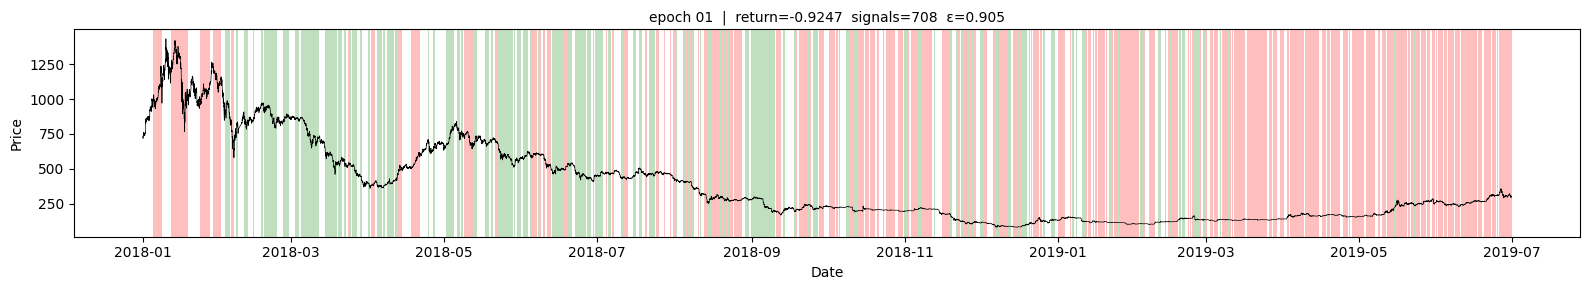

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

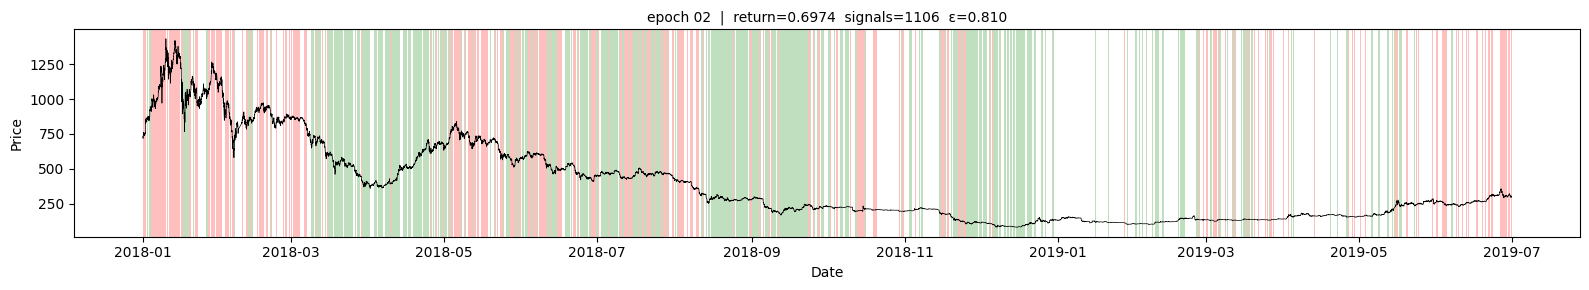

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

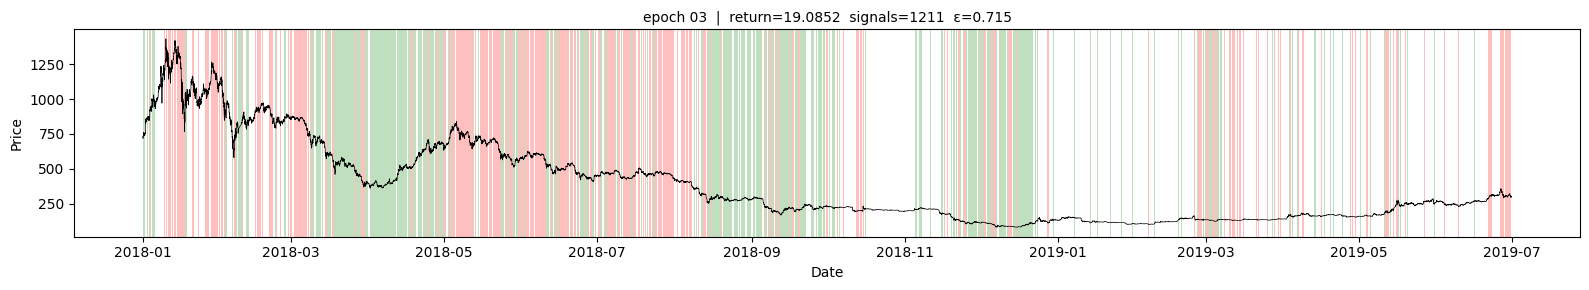

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

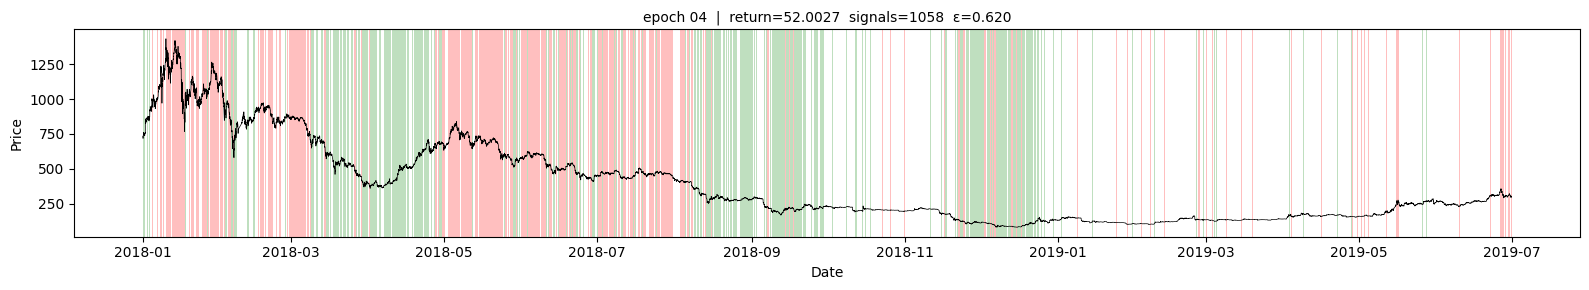

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

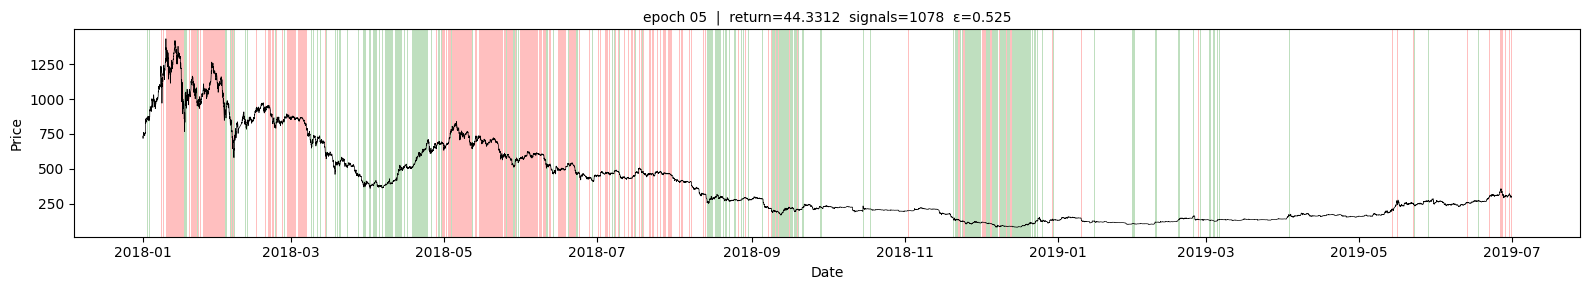

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

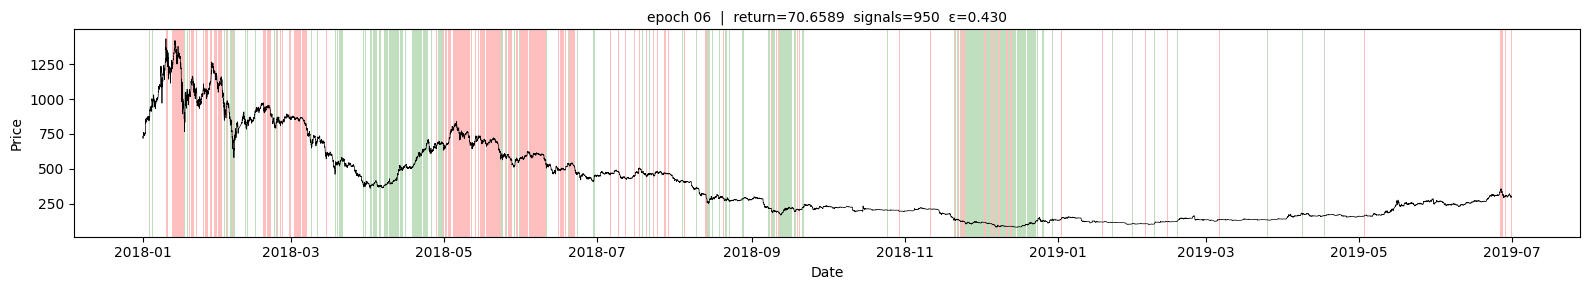

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

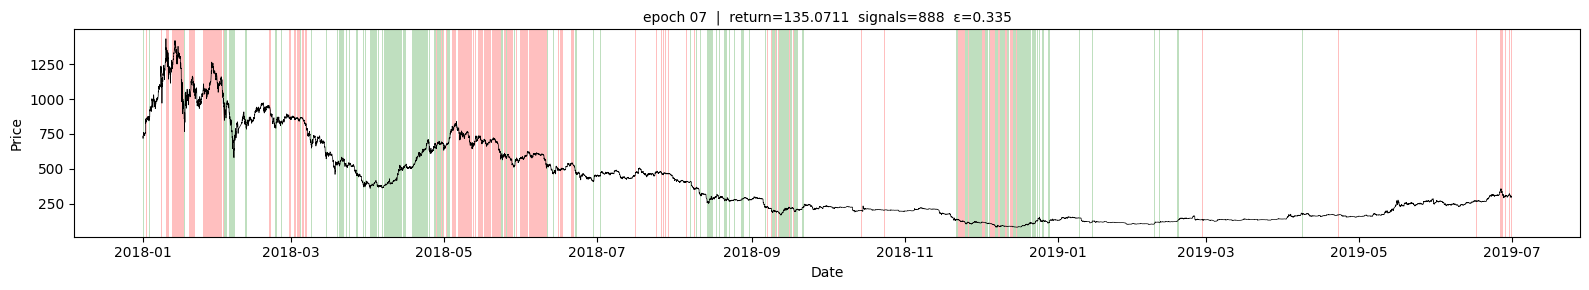

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

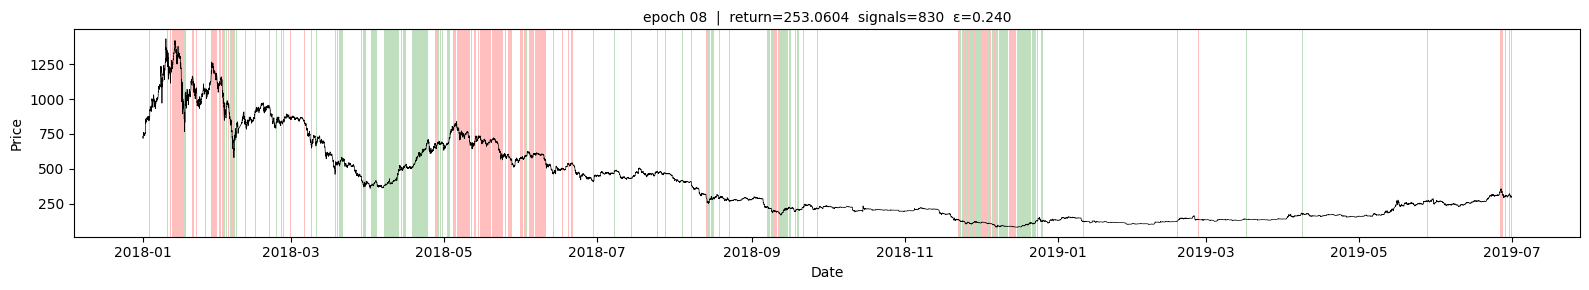

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

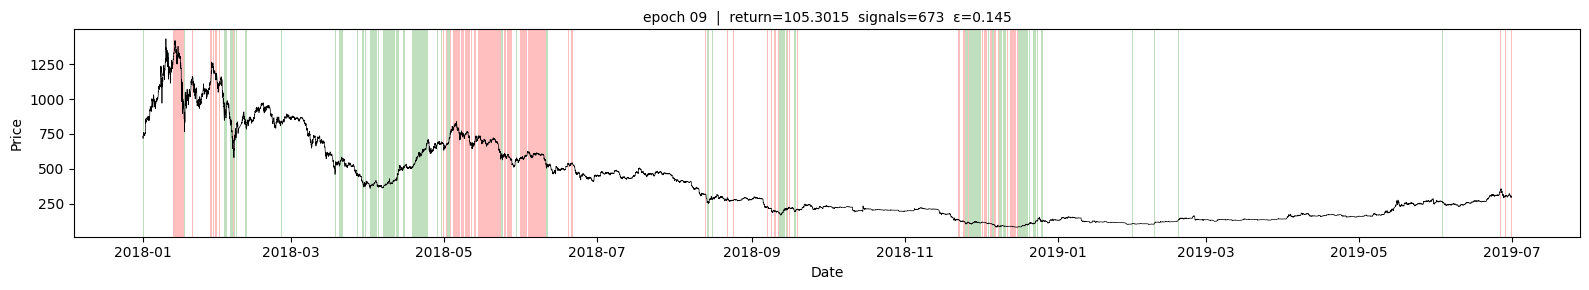

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

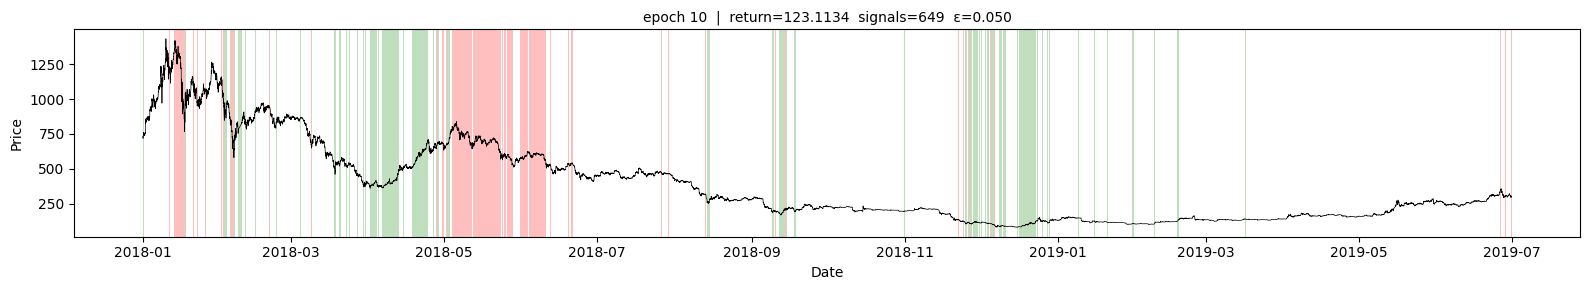

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

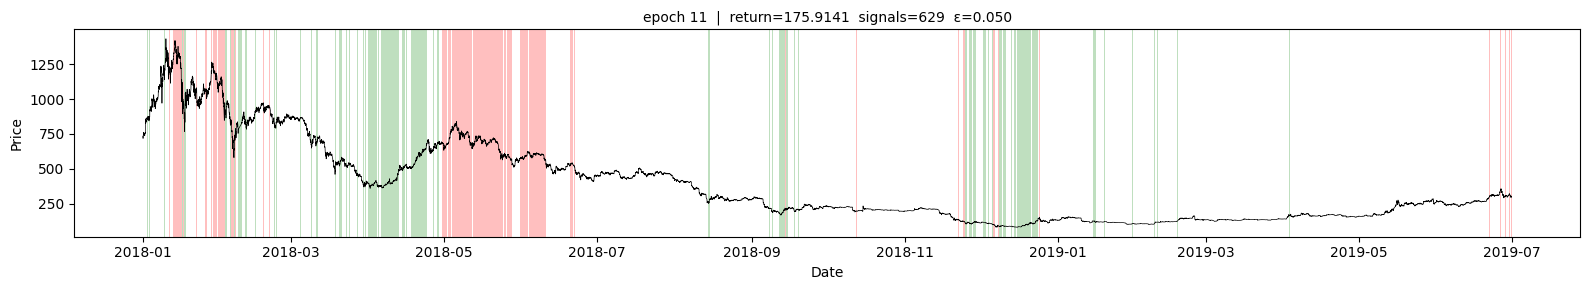

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

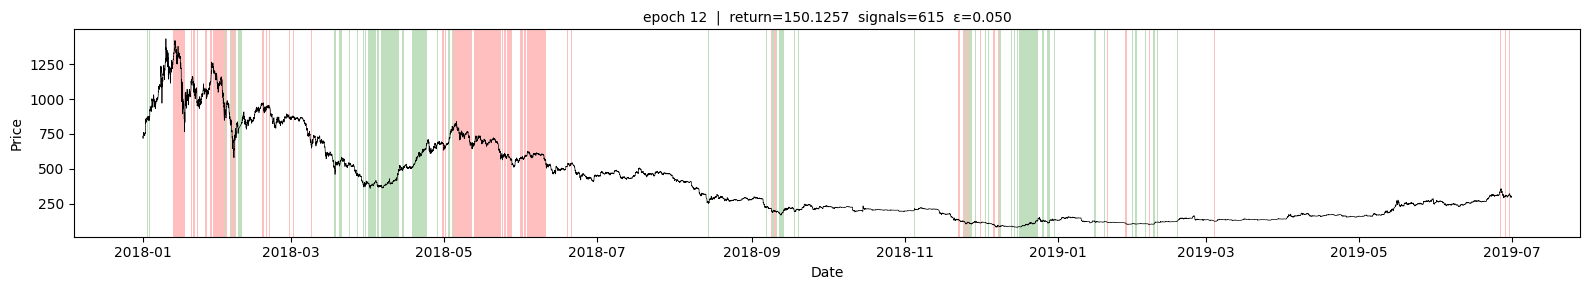

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

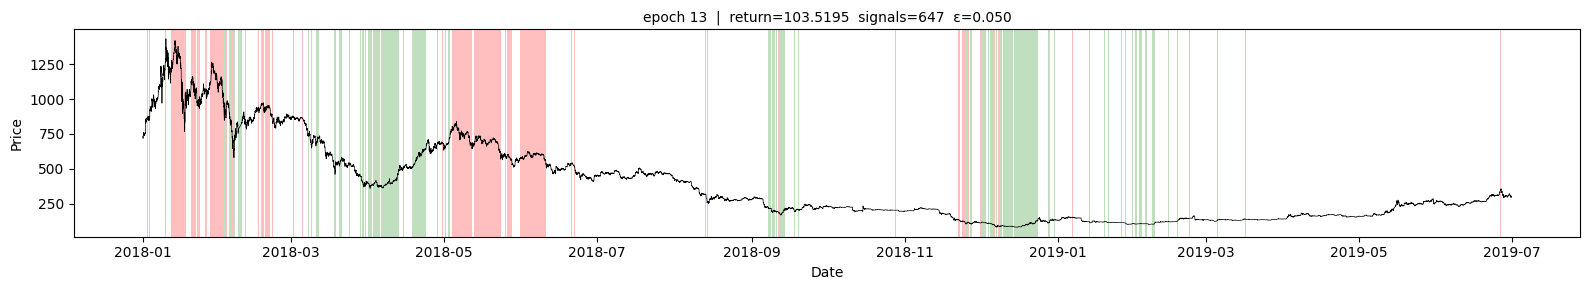

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

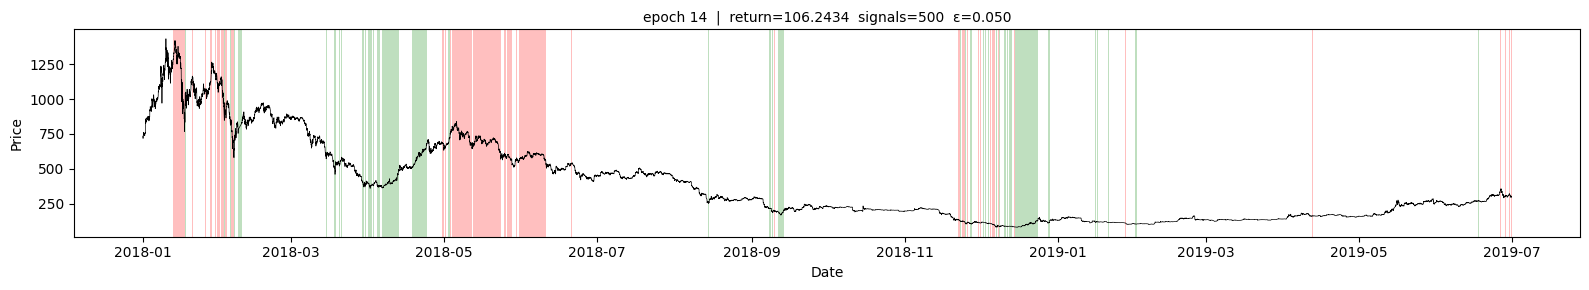

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

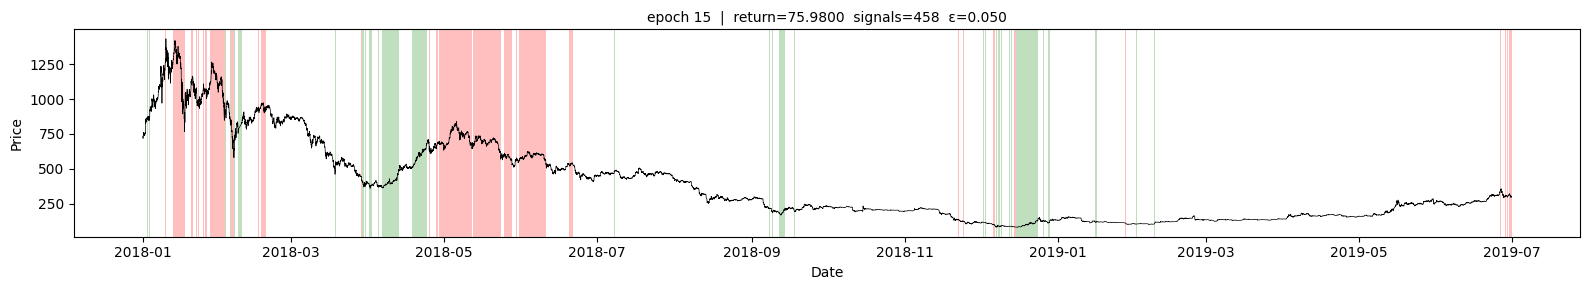

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

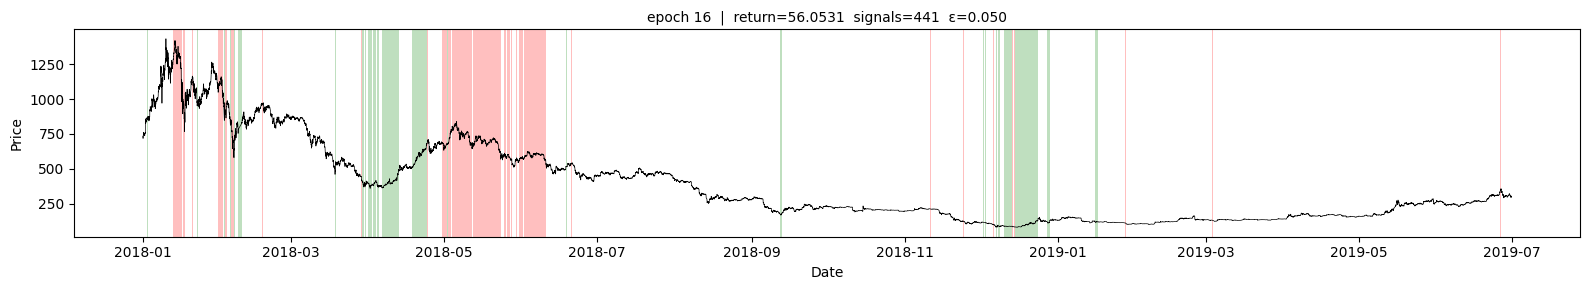

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

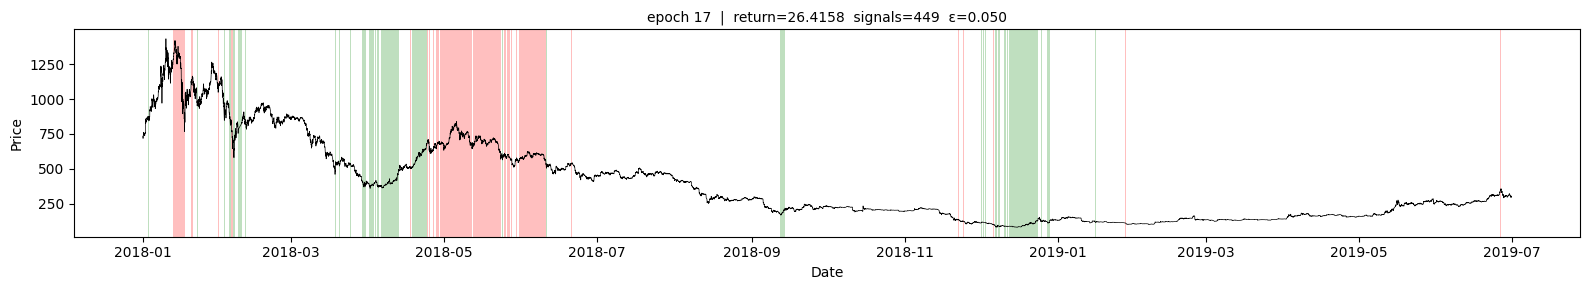

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

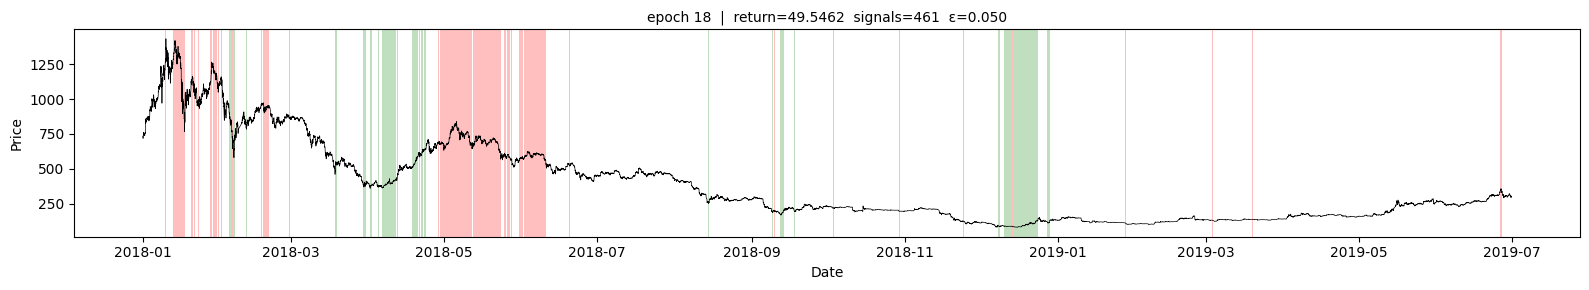

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

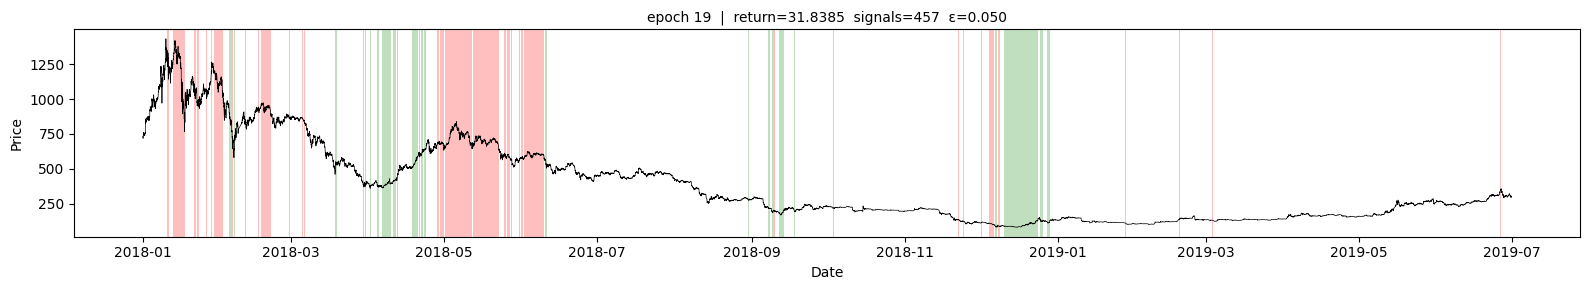

/home/arthur/anaconda3_2026/envs/finrl/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

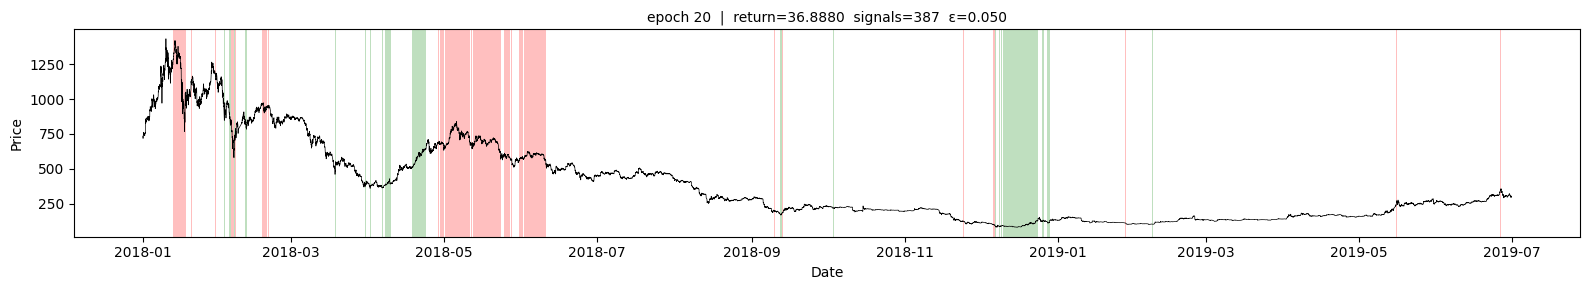

In [8]:
class PlotCallback(BaseCallback):
    """Plots position chart after every episode."""

    def __init__(self, env: AssetVecEnv):
        super().__init__()
        self.env    = env
        self.dates  = pd.to_datetime(env.ts_ary, unit="ns")
        self.prices = env.price_ary
        self.epoch  = 0

    def _on_step(self) -> bool:
        for info in self.locals["infos"]:
            if "episode" not in info:
                continue
            self.epoch += 1
            ep  = info["episode"]
            eps = self.model.exploration_rate
            self._plot(ep, self.epoch, eps)
        return True

    def _plot(self, ep: dict, epoch: int, eps: float) -> None:
        activity   = ep["activity"]
        pos_sparse = activity["position_size"].groupby(level=0).last()
        pos_dense  = (pos_sparse
                      .reindex(self.dates.union(pos_sparse.index))
                      .ffill()
                      .reindex(self.dates)
                      .fillna(0.0))
        direction  = np.sign(pos_dense)

        fig, ax = plt.subplots(figsize=(16, 3))
        ax.plot(self.dates, self.prices, color="black", linewidth=0.5)

        def shade(mask, color):
            i0 = None
            for i, v in enumerate(mask):
                if v and i0 is None:  i0 = i
                elif not v and i0 is not None:
                    ax.axvspan(self.dates[i0], self.dates[i],
                               color=color, alpha=0.25, linewidth=0)
                    i0 = None
            if i0 is not None:
                ax.axvspan(self.dates[i0], self.dates[-1],
                           color=color, alpha=0.25, linewidth=0)

        shade(direction.values ==  1, "green")
        shade(direction.values == -1, "red")

        ax.set_title(f"epoch {epoch:02d}  |  return={ep['r']:.4f}  "
                     f"signals={ep['l']}  ε={eps:.3f}", fontsize=10)
        ax.set_xlabel("Date"); ax.set_ylabel("Price")
        plt.tight_layout(); plt.show()


N_EPOCHS    = 20
total_steps = N_EPOCHS * train_env.T

model.learn(
    total_timesteps     = total_steps,
    callback            = PlotCallback(train_env),
    reset_num_timesteps = True,
    progress_bar        = True,
)

In [9]:
# ── deterministic rollout on train_env ────────────────────────────────────────
obs   = norm_train_env.reset()
done  = np.array([False])
ep    = None

while not done[0]:
    actions, _ = model.predict(obs, deterministic=True)
    obs, _, done, infos = norm_train_env.step(actions)
    if done[0]:
        ep = infos[0]["episode"]

activity = ep["activity"]
print(f"return={ep['r']:.4f}  signals={ep['l']}")

return=31.6717  signals=373


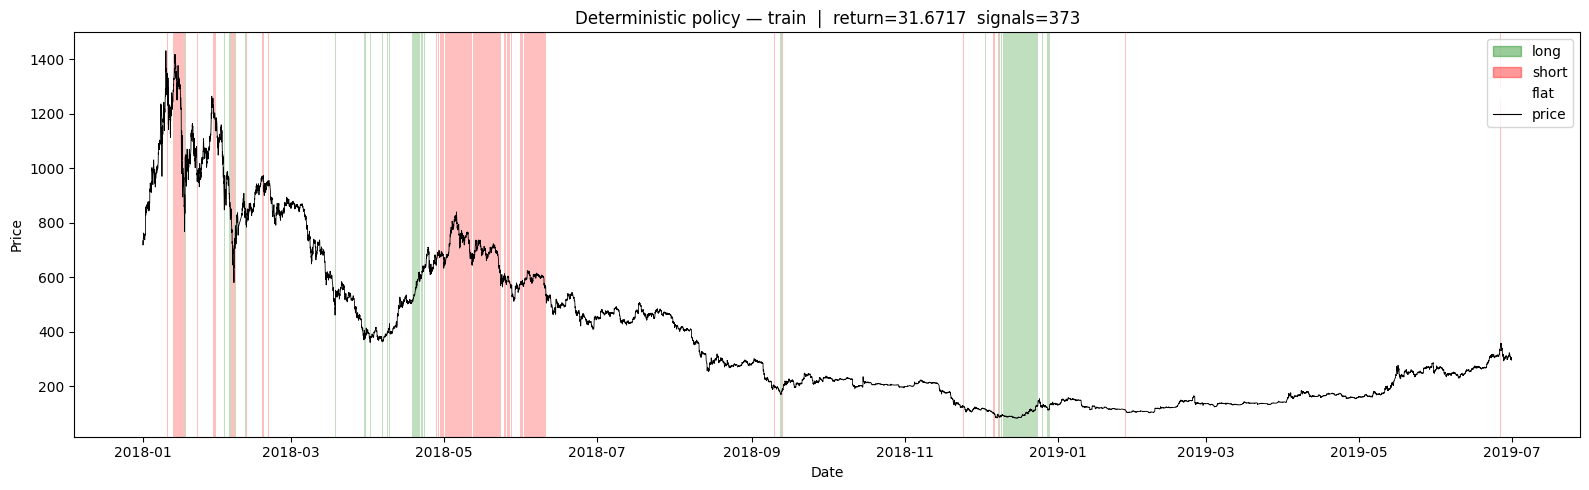

In [10]:
# ── reconstruct dense position series ─────────────────────────────────────────
dates  = pd.to_datetime(train_env.ts_ary, unit="ns")
prices = pd.Series(train_env.price_ary, index=dates)

pos_sparse = activity["position_size"].groupby(level=0).last()
pos_dense  = pos_sparse.reindex(dates.union(pos_sparse.index)).ffill().reindex(dates).fillna(0.0)
direction  = np.sign(pos_dense)

# ── plot ───────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(dates, prices.values, color="black", linewidth=0.6, label="price")

def fill_regions(mask, color, alpha=0.25):
    in_region = False
    for i, active in enumerate(mask):
        if active and not in_region:
            start = dates[i]; in_region = True
        elif not active and in_region:
            ax.axvspan(start, dates[i], color=color, alpha=alpha, linewidth=0)
            in_region = False
    if in_region:
        ax.axvspan(start, dates[-1], color=color, alpha=alpha, linewidth=0)

fill_regions(direction.values ==  1, "green")
fill_regions(direction.values == -1, "red")

ax.set_title(f"Deterministic policy — train  |  return={ep['r']:.4f}  signals={ep['l']}")
ax.set_xlabel("Date"); ax.set_ylabel("Price")
ax.legend(handles=[
    mpatches.Patch(color="green", alpha=0.4, label="long"),
    mpatches.Patch(color="red",   alpha=0.4, label="short"),
    mpatches.Patch(color="white", label="flat"),
    plt.Line2D([0], [0], color="black", linewidth=0.8, label="price"),
])
plt.tight_layout()
plt.show()

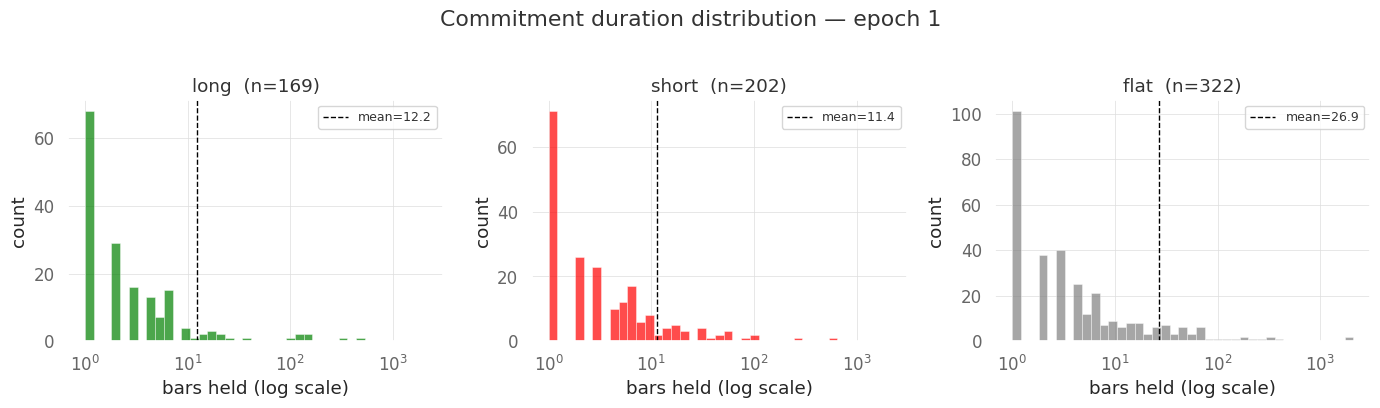

In [195]:
# ── commitment run lengths ─────────────────────────────────────────────────────
# A "commitment" is any contiguous run of the same direction {-1, 0, 1}.
runs   = (direction != direction.shift()).cumsum()
run_df = direction.groupby(runs).agg(length="count", dir="first").reset_index(drop=True)

long_lens  = run_df.loc[run_df["dir"] ==  1, "length"].values
short_lens = run_df.loc[run_df["dir"] == -1, "length"].values
flat_lens  = run_df.loc[run_df["dir"] ==  0, "length"].values

# ── plot ───────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)

bins = np.geomspace(1, max(run_df["length"].max(), 2), 40)

for ax, lens, color, label in zip(
    axes,
    [long_lens, short_lens, flat_lens],
    ["green", "red", "grey"],
    ["long", "short", "flat"],
):
    ax.hist(lens, bins=bins, color=color, alpha=0.7, edgecolor="white", linewidth=0.4)
    ax.axvline(np.mean(lens) if len(lens) else 0, color="black", linestyle="--",
               linewidth=1.0, label=f"mean={np.mean(lens):.1f}" if len(lens) else "no data")
    ax.set_xscale("log")
    ax.set_title(f"{label}  (n={len(lens)})")
    ax.set_xlabel("bars held (log scale)")
    ax.set_ylabel("count")
    ax.legend(fontsize=9)

fig.suptitle("Commitment duration distribution — epoch 1", y=1.02)
plt.tight_layout()
plt.show()


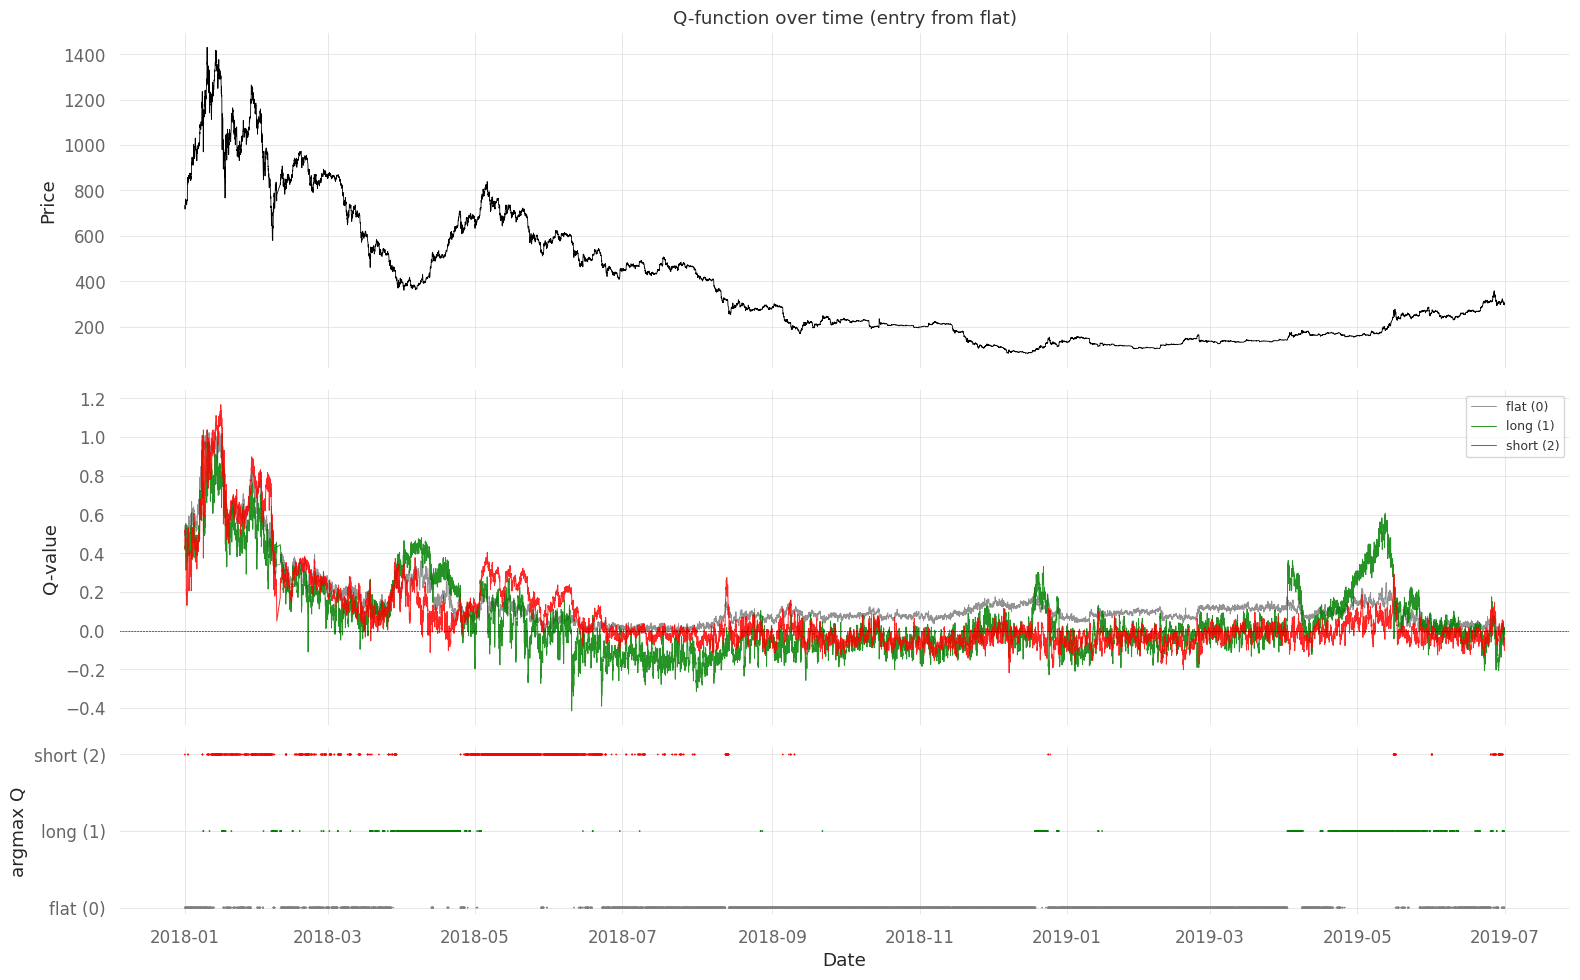

In [196]:
import torch as th

# ── Q-values over time (position fixed to flat=0) ─────────────────────────────
obs_matrix = np.zeros((train_env.T, train_env.observation_space.shape[0]), dtype=np.float32)
obs_matrix[:, 0]  = 0.0
obs_matrix[:, 1:] = train_env.tech_ary

obs_norm = norm_train_env.normalize_obs(obs_matrix)   # apply running stats

model.policy.set_training_mode(False)
with th.no_grad():
    q_vals = model.policy.q_net(
        th.tensor(obs_norm, device=model.device)
    ).cpu().numpy()   # (T, 3)

dates  = pd.to_datetime(train_env.ts_ary, unit="ns")
prices = train_env.price_ary
labels = ["flat (0)", "long (1)", "short (2)"]
colors = ["grey", "green", "red"]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(16, 10), sharex=True,
                                     gridspec_kw={"height_ratios": [2, 2, 1]})
ax1.plot(dates, prices, color="black", linewidth=0.6)
ax1.set_ylabel("Price")
ax1.set_title("Q-function over time (entry from flat)")

for i, (lbl, col) in enumerate(zip(labels, colors)):
    ax2.plot(dates, q_vals[:, i], label=lbl, color=col, linewidth=0.7, alpha=0.85)
ax2.axhline(0, color="black", linewidth=0.4, linestyle="--")
ax2.set_ylabel("Q-value")
ax2.legend(loc="upper right", fontsize=9)

best = q_vals.argmax(axis=1)
ax3.scatter(dates, best, c=[colors[a] for a in best], s=1.5, linewidths=0)
ax3.set_yticks([0, 1, 2]); ax3.set_yticklabels(labels)
ax3.set_ylabel("argmax Q")
ax3.set_xlabel("Date")

plt.tight_layout()
plt.show()

In [197]:
from backtest import price_series_from_env, infer_periods, activity_to_equity, activity_to_returns, metrics

price   = price_series_from_env(train_env)
periods = infer_periods(price)
equity  = activity_to_equity(activity, price)
returns = activity_to_returns(activity, price)

m = metrics(returns, equity, periods)
pd.Series(m).round(4)

sharpe             5.4359
sortino            9.6025
calmar           150.7011
cagr              42.2015
max_drawdown      -0.9021
volatility         0.7429
omega              1.3776
profit_factor      1.3776
win_rate           0.4995
var_95            -0.0126
dtype: float64

initial equity :   10000.00
final equity   : 2692235.00
net P&L        : 2682235.00  (26822.4%)
n trades       : 743


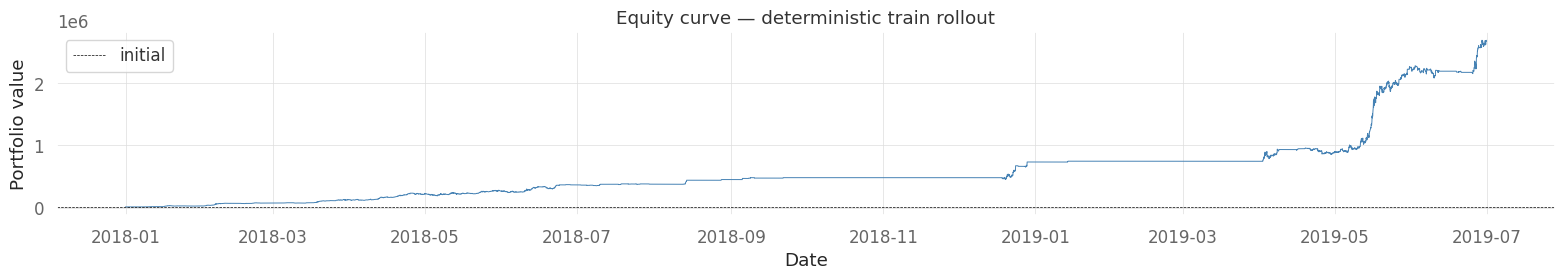

In [198]:
# ── commission vs directional P&L decomposition ───────────────────────────────
# total_commission = activity["commission"].sum()
initial_cash     = equity.iloc[0]
final_equity     = equity.iloc[-1]
net_pnl          = final_equity - initial_cash
# gross_pnl        = net_pnl + total_commission          # what you'd have without commissions

print(f"initial equity : {initial_cash:>10.2f}")
print(f"final equity   : {final_equity:>10.2f}")
print(f"net P&L        : {net_pnl:>10.2f}  ({net_pnl/initial_cash*100:.1f}%)")
# print(f"gross P&L      : {gross_pnl:>10.2f}  ({gross_pnl/initial_cash*100:.1f}%)")
# print(f"total commission: {total_commission:>9.2f}  ({total_commission/initial_cash*100:.1f}%)")
print(f"n trades       : {ep['l']}")
# print(f"avg commission / trade: {total_commission/max(ep['l'],1):.4f}")

# ── equity curve ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 3))
ax.plot(equity.index, equity.values, color="steelblue", linewidth=0.7)
ax.axhline(initial_cash, color="black", linewidth=0.5, linestyle="--", label="initial")
ax.set_title("Equity curve — deterministic train rollout")
ax.set_ylabel("Portfolio value"); ax.set_xlabel("Date")
ax.legend(); plt.tight_layout(); plt.show()

In [199]:
# ── sync normalisation stats from training ────────────────────────────────────
norm_val_env.obs_rms  = norm_train_env.obs_rms
norm_test_env.obs_rms = norm_train_env.obs_rms


def deterministic_rollout(norm_env, raw_env, label):
    """Run one full episode deterministically. Returns (ep, activity)."""
    obs  = norm_env.reset()
    done = np.array([False])
    ep   = None
    while not done[0]:
        actions, _ = model.predict(obs, deterministic=True)
        obs, _, done, infos = norm_env.step(actions)
        if done[0]:
            ep = infos[0]["episode"]
    print(f"{label:5s}  return={ep['r']:.4f}  signals={ep['l']}")
    return ep, ep["activity"]


ep_val,  act_val  = deterministic_rollout(norm_val_env,  val_env,  "val")
ep_test, act_test = deterministic_rollout(norm_test_env, test_env, "test")


val    return=-0.3334  signals=532
test   return=-0.6458  signals=286


── Validation ──
sharpe          -0.7828
sortino         -1.0952
calmar          -1.0796
cagr            -0.5550
max_drawdown    -0.9342
volatility       0.7105
omega            0.9729
profit_factor    0.9729
win_rate         0.4858
var_95          -0.0125


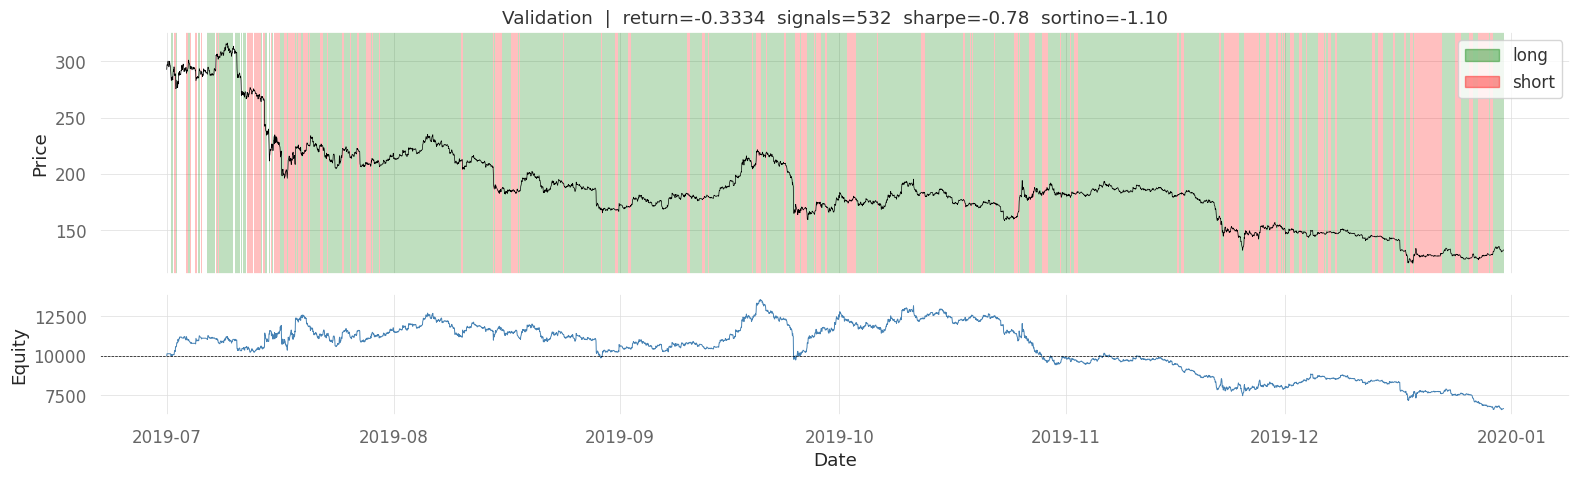

── Test ──
sharpe          -2.9323
sortino         -3.8609
calmar          -1.3888
cagr            -0.9847
max_drawdown    -0.9665
volatility       1.1816
omega            0.8997
profit_factor    0.8997
win_rate         0.4822
var_95          -0.0212


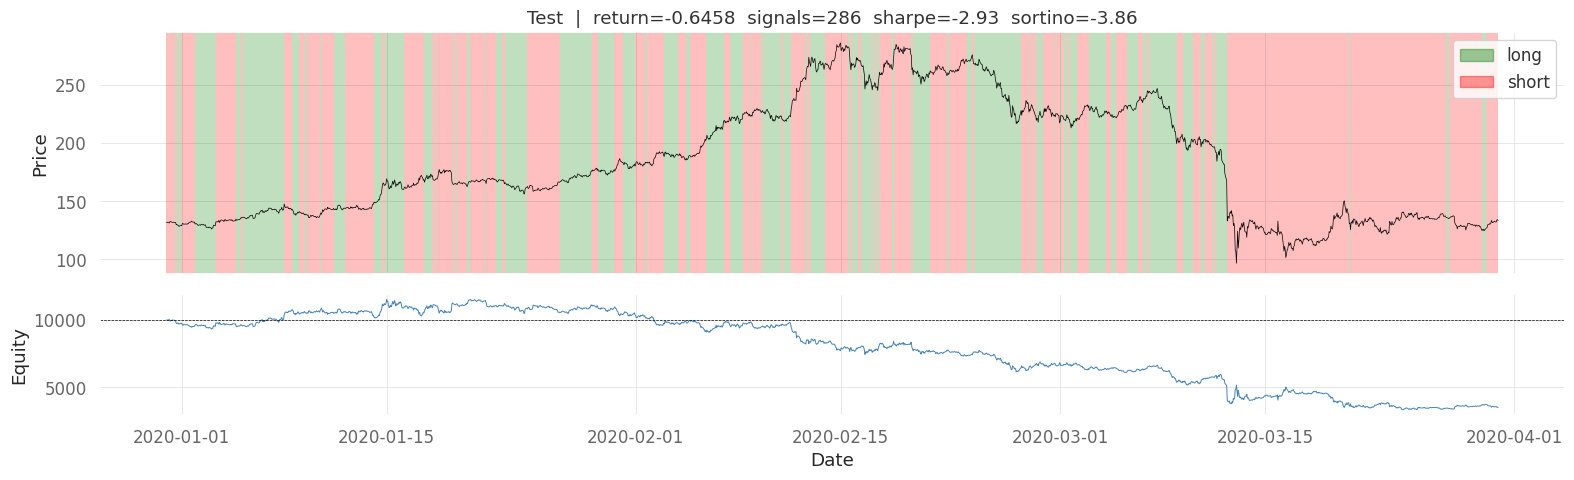

In [200]:
from backtest import price_series_from_env, infer_periods, activity_to_equity, activity_to_returns, metrics


def validate(raw_env, ep, activity, label):
    price   = price_series_from_env(raw_env)
    periods = infer_periods(price)
    equity  = activity_to_equity(activity, price)
    returns = activity_to_returns(activity, price)
    m       = metrics(returns, equity, periods)

    print(f"── {label} ──")
    print(pd.Series(m).round(4).to_string())

    dates   = pd.to_datetime(raw_env.ts_ary, unit="ns")
    prices  = pd.Series(raw_env.price_ary, index=dates)

    pos_sparse = activity["position_size"].groupby(level=0).last()
    pos_dense  = (pos_sparse
                  .reindex(dates.union(pos_sparse.index))
                  .ffill().reindex(dates).fillna(0.0))
    direction  = np.sign(pos_dense)

    fig, axes = plt.subplots(2, 1, figsize=(16, 5), sharex=True,
                              gridspec_kw={"height_ratios": [2, 1]})

    ax = axes[0]
    ax.plot(dates, prices.values, color="black", linewidth=0.5)
    for val, color in [(1, "green"), (-1, "red")]:
        mask = direction.values == val
        in_r = False
        for i, v in enumerate(mask):
            if v and not in_r:  start = dates[i]; in_r = True
            elif not v and in_r:
                ax.axvspan(start, dates[i], color=color, alpha=0.25, linewidth=0)
                in_r = False
        if in_r: ax.axvspan(start, dates[-1], color=color, alpha=0.25, linewidth=0)
    ax.set_title(f"{label}  |  return={ep['r']:.4f}  signals={ep['l']}  "
                 f"sharpe={m['sharpe']:.2f}  sortino={m['sortino']:.2f}")
    ax.set_ylabel("Price")
    ax.legend(handles=[
        mpatches.Patch(color="green", alpha=0.4, label="long"),
        mpatches.Patch(color="red",   alpha=0.4, label="short"),
    ])

    ax2 = axes[1]
    ax2.plot(equity.index, equity.values, color="steelblue", linewidth=0.7)
    ax2.axhline(equity.iloc[0], color="black", linewidth=0.5, linestyle="--")
    ax2.set_ylabel("Equity"); ax2.set_xlabel("Date")

    plt.tight_layout(); plt.show()


validate(val_env,  ep_val,  act_val,  "Validation")
validate(test_env, ep_test, act_test, "Test")
